<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20Regresi%20PBL/Praktikum%201%20(JS6R).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Persiapan Data

#Langkah 2: Import Library

In [1]:
# Import package dasar
import numpy as np
import pandas as pd

#Langkah 3: Baca dan Gabungkan Data (cafes.csv & reviews.csv)

In [2]:
# Baca data dari kedua file CSV
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

# Agregasi data reviews per kafe
cafe_reviews = reviews.groupby('cafe_id').agg({
    'rating': 'mean',
    'likes': 'sum',
    'review_id': 'count'
}).reset_index()

cafe_reviews.rename(columns={
    'rating': 'avg_review_rating',
    'likes': 'total_likes',
    'review_id': 'total_reviews_dataset'
}, inplace=True)

# Gabungkan dataset cafes dan hasil agregasi reviews
data = pd.merge(cafes, cafe_reviews, on='cafe_id', how='inner')
print("Berhasil menggabungkan dataset. Ukuran data:", data.shape)

Berhasil menggabungkan dataset. Ukuran data: (94, 15)


#Langkah 4: Pemahaman Terhadap Data

In [3]:
# Melihat beberapa data awal
display(data.head())

# Mengecek ukuran data (baris, kolom)
print("Ukuran data:", data.shape)

# Informasi tentang tipe data dan missing value
data.info()

# Deskripsi statistik data
data.describe()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query,avg_review_rating,total_likes,total_reviews_dataset
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang,4.400000,0,30
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang,4.866667,0,30
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,NaN,2026-10-11T13:55:10.909678,cafe Kota Malang,4.217391,0,23
3,f4cd572c-a98d-4309-aa81-6018d889c9d6,Zocco Heritage,"Jl. Raya Lawang - Malang No.34, Klojen, Purwan...",-7.967561,112.633346,4.3,701,['Kedai Kopi'],NaN,instagram.com,2026-10-11T13:55:27.732707,cafe Kota Malang,4.133333,0,30
4,fdd5baff-4477-4188-abf8-4f2a00cf10ee,RASWARA COFFEE AND EATERY,"Jl. Suropati No.1, Klojen, Kec. Klojen, Kota M...",-7.976481,112.634028,4.3,686,['Kafe'],0822-3131-2363,instagram.com,2026-10-11T13:55:43.558923,cafe Kota Malang,3.666667,0,30


Ukuran data: (94, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cafe_id                94 non-null     object 
 1   name                   94 non-null     object 
 2   address                94 non-null     object 
 3   latitude               94 non-null     float64
 4   longitude              94 non-null     float64
 5   rating                 94 non-null     float64
 6   review_count           94 non-null     int64  
 7   categories             94 non-null     object 
 8   phone                  74 non-null     object 
 9   website                51 non-null     object 
 10  scraped_at             94 non-null     object 
 11  source_query           94 non-null     object 
 12  avg_review_rating      94 non-null     float64
 13  total_likes            94 non-null     int64  
 14  total_reviews_dataset  94 non-null    

,latitude,longitude,rating,review_count,avg_review_rating,total_likes,total_reviews_dataset
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000
mean,-7.964979,112.627496,4.665957,886.393617,4.568319,0.882979,23.723404
std,0.010242,0.007309,0.176923,1247.618551,0.405073,2.422371,10.069014
min,-7.985575,112.607256,4.200000,1.000000,2.600000,0.000000,1.000000
25%,-7.972556,112.622708,4.600000,141.000000,4.400000,0.000000,20.250000
50%,-7.966182,112.627024,4.700000,523.000000,4.700000,0.000000,30.000000
75%,-7.960720,112.632884,4.800000,1074.750000,4.811111,1.000000,30.000000
max,-7.932842,112.651831,5.000000,6014.000000,5.000000,14.000000,30.000000


#Langkah 5: Visualisasi Data

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


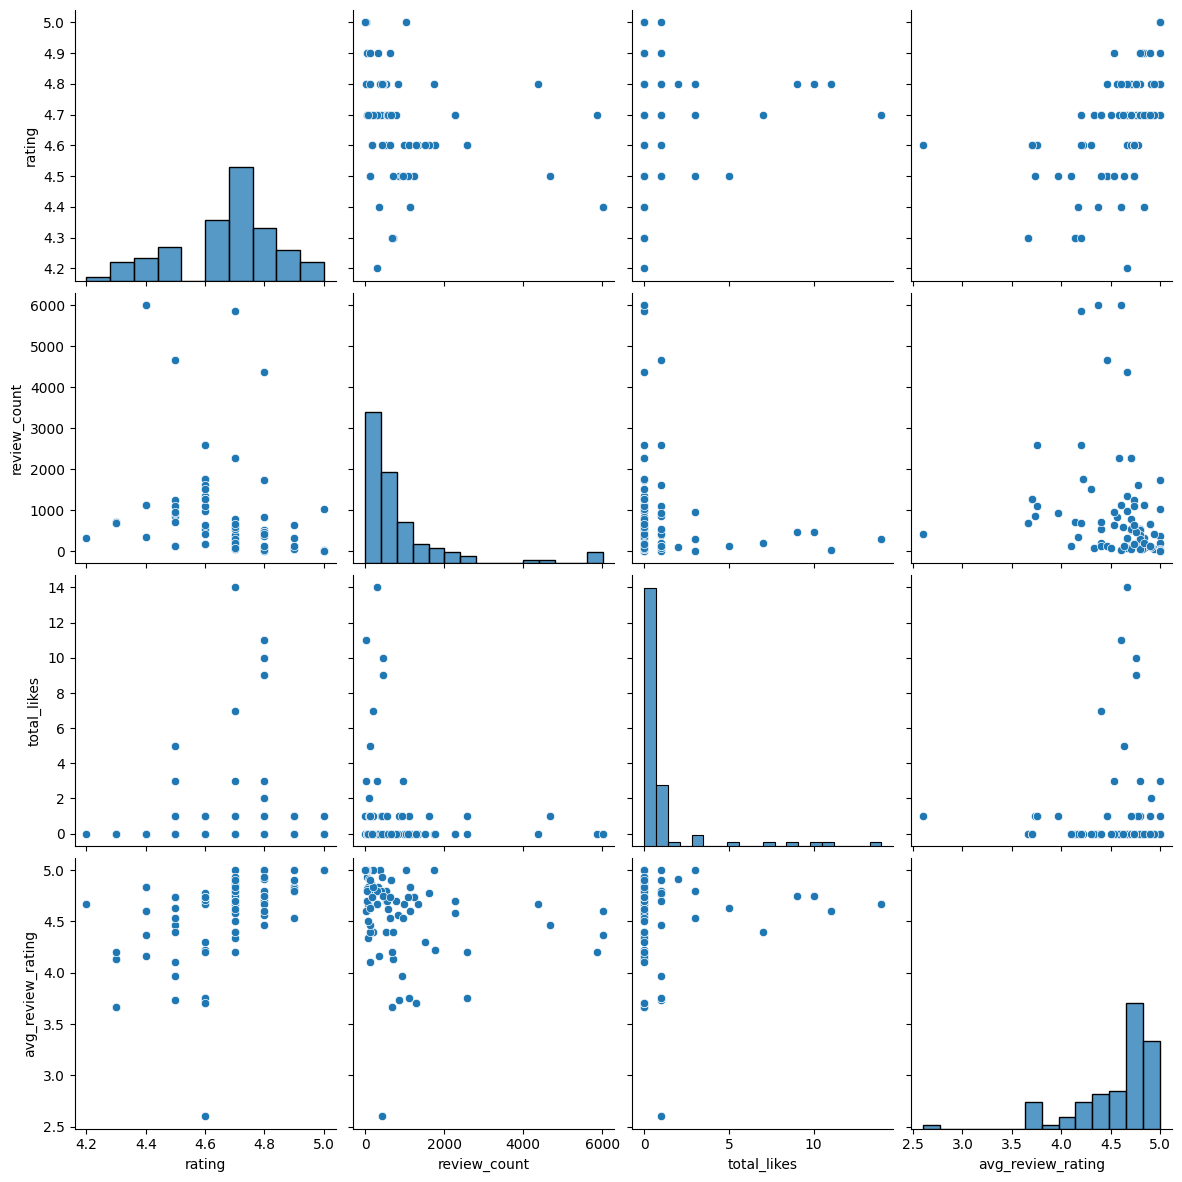

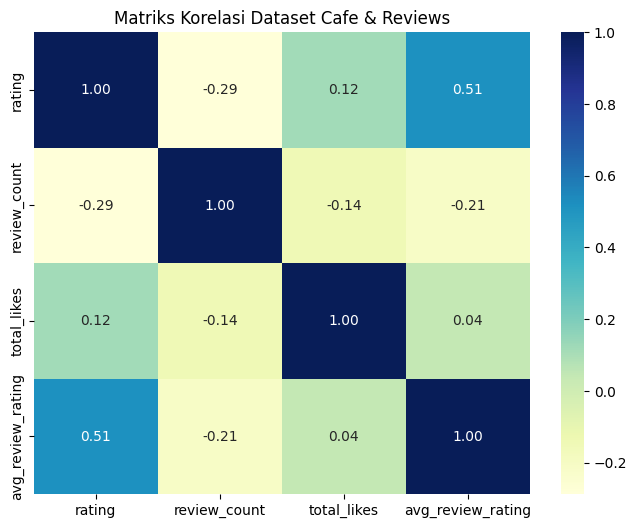

In [4]:
# Import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi data dengan pairplot (memilih beberapa kolom numerik yang relevan)
sns.pairplot(data[['rating', 'review_count', 'total_likes', 'avg_review_rating']],
             size=3, aspect=1, kind='scatter')
plt.show()

# Visualisasi korelasi dengan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(data[['rating', 'review_count', 'total_likes', 'avg_review_rating']].corr(),
            cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Matriks Korelasi Dataset Cafe & Reviews")
plt.show()

#Langkah 6: Regresi Linier

In [5]:
# Membuat variabel bebas X dan target y
X = data['review_count']
y = data['rating']

In [6]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [7]:
# Training model Regresi Linier menggunakan StatsModels
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

# Menampilkan ringkasan hasil regresi
print(lr.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     5.736
Date:                Sat, 14 Nov 2026   Prob (F-statistic):             0.0196
Time:                        04:56:06   Log-Likelihood:                 23.162
No. Observations:                  65   AIC:                            -42.32
Df Residuals:                      63   BIC:                            -37.97
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            4.6967      0.026    178.782   

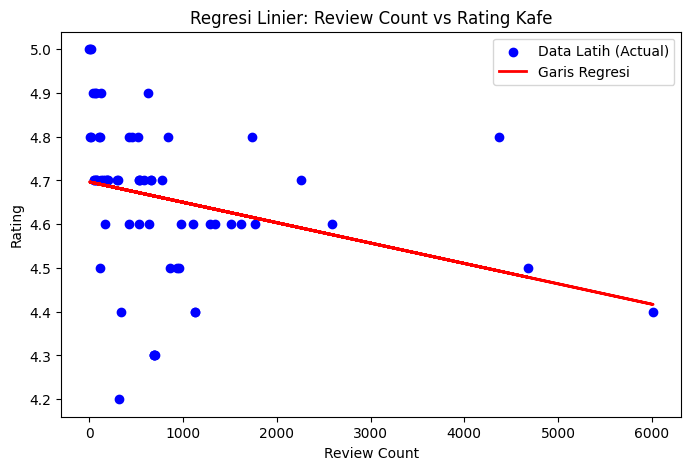

In [8]:
# Mengambil nilai intercept dan koefisien slope dari hasil training
intercept = lr.params['const']
slope = lr.params['review_count']

# Visualisasi garis regresi pada data latih
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', label='Data Latih (Actual)')
plt.plot(X_train, intercept + slope * X_train, color='red', linewidth=2, label='Garis Regresi')
plt.xlabel('Review Count')
plt.ylabel('Rating')
plt.title('Regresi Linier: Review Count vs Rating Kafe')
plt.legend()
plt.show()

#Langkah 7: Analisis Residual

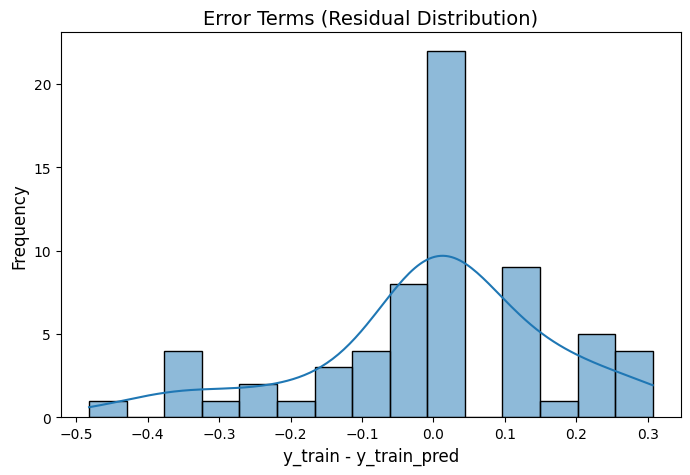

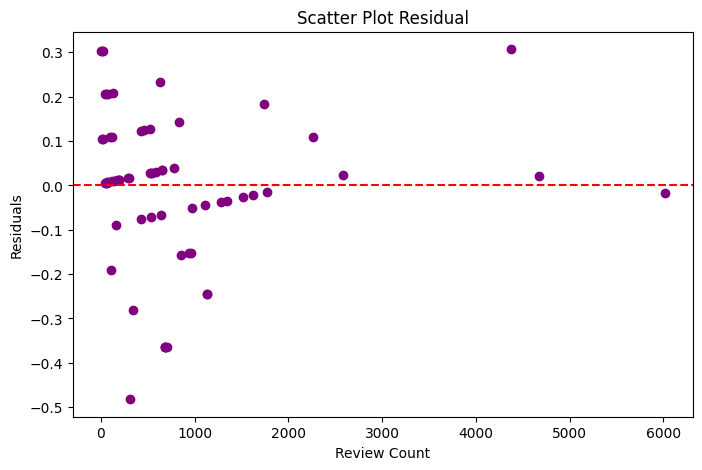

In [9]:
# Prediksi nilai y dari data x latih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual (error terms)
res = (y_train - y_train_pred)

# Histogram residual
fig = plt.figure(figsize=(8, 5))
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms (Residual Distribution)', fontsize=14)
plt.xlabel('y_train - y_train_pred', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

# Scatter plot residual terhadap X_train
plt.figure(figsize=(8, 5))
plt.scatter(X_train, res, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Review Count')
plt.ylabel('Residuals')
plt.title('Scatter Plot Residual')
plt.show()

#Langkah 8: Prediksi pada Data Uji dan Evaluasi Model

In [10]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# Hitung nilai R-squared
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_test_pred)
print(f"Nilai R-squared pada Data Uji: {r2:.4f}")

Nilai R-squared pada Data Uji: 0.0563


#Langkah 9: Visualisasi Hasil

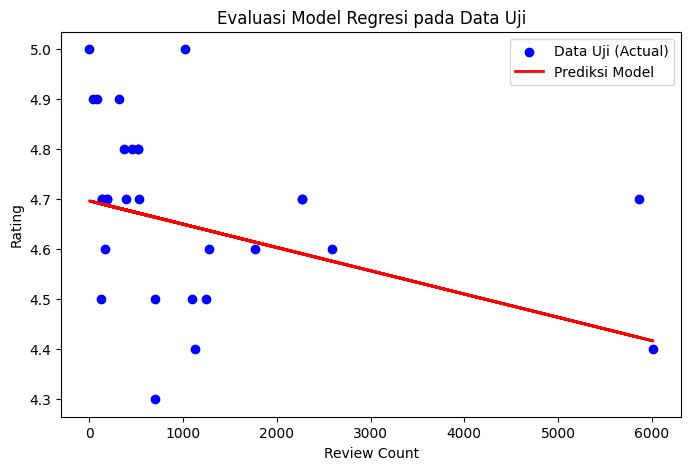

In [11]:
# Visualisasi data uji dan hasil prediksi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Data Uji (Actual)')
plt.plot(X_test, y_test_pred, color='red', linewidth=2, label='Prediksi Model')
plt.xlabel('Review Count')
plt.ylabel('Rating')
plt.title('Evaluasi Model Regresi pada Data Uji')
plt.legend()
plt.show()